# Homework 11


**Concepts covered:**

pandas `DataFrame`s: grouping data, querying `DataFrame`s, joining multiple `DataFrame`s, sampling.

**Instructions:**

Be sure to run each code block after you edit it to make sure it runs as expected. When you are done, we strongly recommend you run all the code from scratch (Runtime menu -> Restart and Run all) to make sure your current code works for all problems.

If your code raises an exception when run from scratch, it will interfere with the auto-grader process causing you to lose some or all points for this homework. Please ask for help on Piazza, attend office hours or schedule an appointment with your learning facilitator if you get stuck.

**Warning against using generative AI:**

We recommend *in the strongest terms* against using generative AI in solving any homework assignment in this module. The goal of these assignments is for you to learn the fundamental concepts about programming: syntax, correctness, problem decomposition, and skepticism. While we know that generative AI can solve all of these problems, you will not be learning anything and will get confused as this module progresses.

While we encourage you to use AI to generate practice problems, you should try to solve these problems with the help of the sample problems, and examples on blackboard and experimentation.


**Docstrings and Comments:**

Include a *documentation string* (docstring) for each function definition, as well as comments in the body of your code to explain each control structures (e.g., decision, loop), function call, or formula.

## Shared Imports

Do not install or use any additional modules.
Installing additional modules may result in an autograder failure resulting in zero points for some or all problems.

In [1]:
# shared imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.close("all")


**Note: This assignment is partially manually graded, so please allow some time for you to get your final scores.**

**Review Problem 1**

**Concept:** *`DataFrame`: initialization, line plots.*

**Task:**


Using the Starbucks stock dataset:

1. Load the `SBUX.csv` dataset into a DataFrame named `df_sbux`.
2. Convert the `date` column to a pandas datetime format and set it as the index.
3. Create a line plot showing both the `high` and `low` prices over time.

Your plot should include:

* both high and low columns plotted together
* a title
* a key


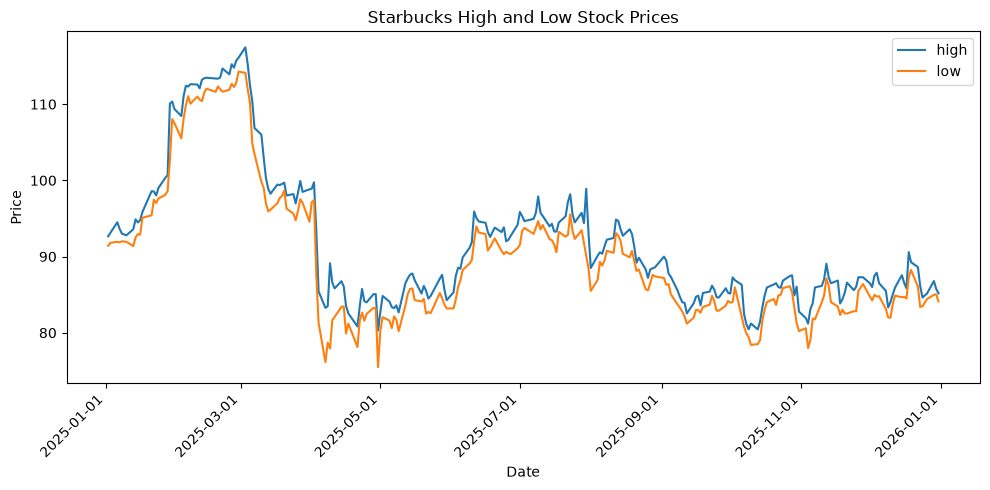

In [11]:
# Your Solution

# Load data
df_sbux = pd.read_csv("SBUX.csv")


df_sbux["date"] = pd.to_datetime(df_sbux["date"], unit="s").dt.normalize()
df_sbux = df_sbux.set_index("date").sort_index()

df_sbux

# Plot 
ax = df_sbux[["high", "low"]].plot(
    title="Starbucks High and Low Stock Prices",
    xlabel="Date",
    ylabel="Price",
    legend=True,
    rot=45,
    figsize=(10, 5),
)

ax.xaxis.set_major_formatter(
    plt.matplotlib.dates.DateFormatter("%Y-%m-%d")
)
plt.tight_layout()
# Display the chart.
#plt.show()

Review Problem 2

**Concept:** *`DataFrame`: initialization, descriptive statistics, histogram.*

**Task:**

Using the `SBUX.csv` dataset:

1. Load the dataset into a DataFrame named `df_sbux`.
2. Convert the `date` column to a pandas datetime format and set it as the index.
3. Compute the **daily return** of the stock using the `close` column (percentage change).
4. Display the **descriptive statistics** of the daily returns.
5. Create a **histogram** of the daily returns using 25 bins.
6. Identify **outliers** where the return falls outside of **mean ± 3 standard deviations**.
7. Print:
    *  the upper and lower bounds
    * the number of values above and below these bounds
    * the list of outlier values (sorted by date)


Daily return statistics (%):
count    249.000000
mean      -0.013012
std        2.160067
min      -11.216177
25%       -1.133576
50%        0.010747
75%        1.132297
max       11.281212
Name: close, dtype: float64


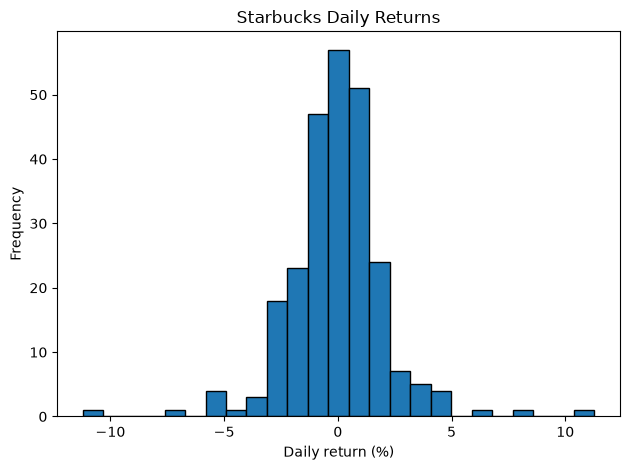

In [ ]:
# Your Solution
df_sbux = pd.read_csv("SBUX.csv")
df_sbux["date"] = pd.to_datetime(df_sbux["date"], unit="s").dt.normalize()
df_sbux = df_sbux.set_index("date").sort_index()

# Compute returns as percentages
daily_returns = df_sbux["close"].pct_change(fill_method=None).dropna() * 100

# Display descriptive statistics
print("Daily return statistics (%):")
print(daily_returns.describe())

# Plot the distribution using 25 bins.
daily_returns.plot.hist(
    bins=25,
    title="Starbucks Daily Returns",
    edgecolor="black",
)
plt.xlabel("Daily return (%)")
plt.ylabel("Frequency")
plt.tight_layout()





Test case for problem 2

In [17]:
# Test Case:

# Calculate bounds three standard deviations from the mean.
mean_return = daily_returns.mean()
std_return = daily_returns.std()
lower_bound = mean_return - 3 * std_return
upper_bound = mean_return + 3 * std_return

# Identify returns 
below = daily_returns < lower_bound
above = daily_returns > upper_bound
outliers = daily_returns[below | above].sort_index()

# Print bounds, counts, and all outlier values in date order.
print(f"\nLower bound: {lower_bound:.4f}%")
print(f"Upper bound: {upper_bound:.4f}%")
print(f"Number below lower bound: {below.sum()}")
print(f"Number above upper bound: {above.sum()}")
print("\nOutlier daily returns (%), sorted by date:")
print(outliers.to_string())


Lower bound: -6.4932%
Upper bound: 6.4672%
Number below lower bound: 2
Number above upper bound: 3

Outlier daily returns (%), sorted by date:
date
2025-01-29     8.136638
2025-04-03   -11.216177
2025-04-04    -6.979383
2025-04-09    11.281212
2025-05-12     6.687416


**Problem 3**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Load the dataset into a DataFrame named `df_weather`.
2. Convert the `datetime` column to a pandas datetime format and set it as the index.
3. Use the icon column as a categorical variable and group the data by `icon`.
4. Create a **pie chart** showing the count of each weather icon category.

Your chart should include:
* labels for each category
* a title



/var/folders/zc/_6m899y94fn0gf0rwp8g4cv80000gn/T/ipykernel_2952/4236064688.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_weather["datetime"] = pd.to_datetime(df_weather["datetime"])


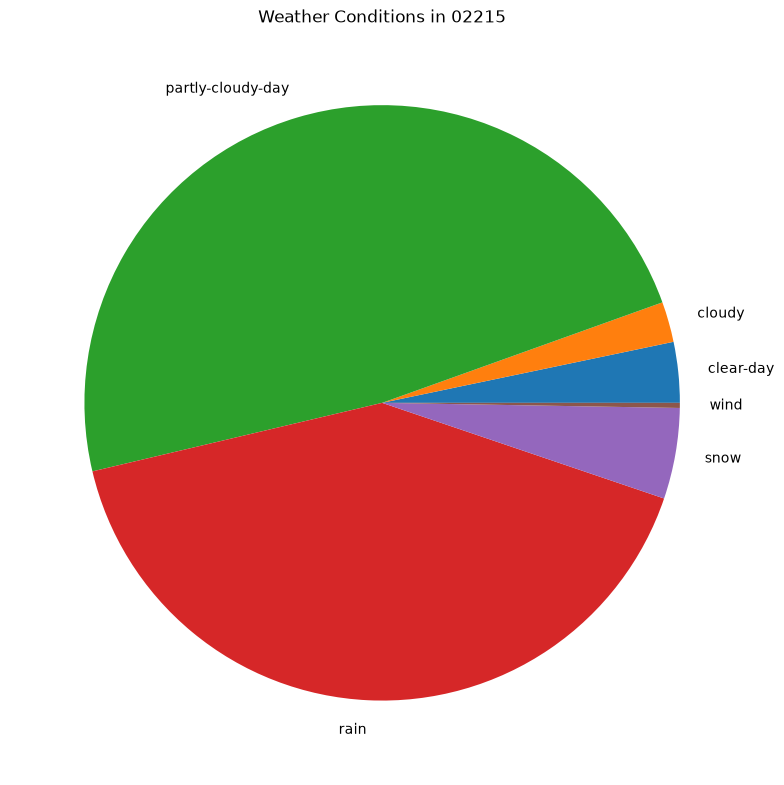

In [18]:
# Your Solution
# Load weather data and set a datetime index.
df_weather = pd.read_csv("02215_weather.csv")
df_weather["datetime"] = pd.to_datetime(df_weather["datetime"])
df_weather = df_weather.set_index("datetime").sort_index()

# Convert icons to categories and group observations by icon.
df_weather["icon"] = df_weather["icon"].astype("category")
grouped_by_icon = df_weather.groupby("icon", observed=True)

# Count observations in each weather category.
icon_counts = grouped_by_icon.size()

# Plot category counts with labels and a title.
icon_counts.plot.pie(
    title="Weather Conditions in 02215",
    ylabel="",
    figsize=(8, 8),
)
plt.tight_layout()




**Problem 4**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Create a **histogram** of the `tempmax` column for each weather condition group.

Your plot should include:
* 25 bins
* transparency so overlapping distributions can be seen
* a legend
* a title


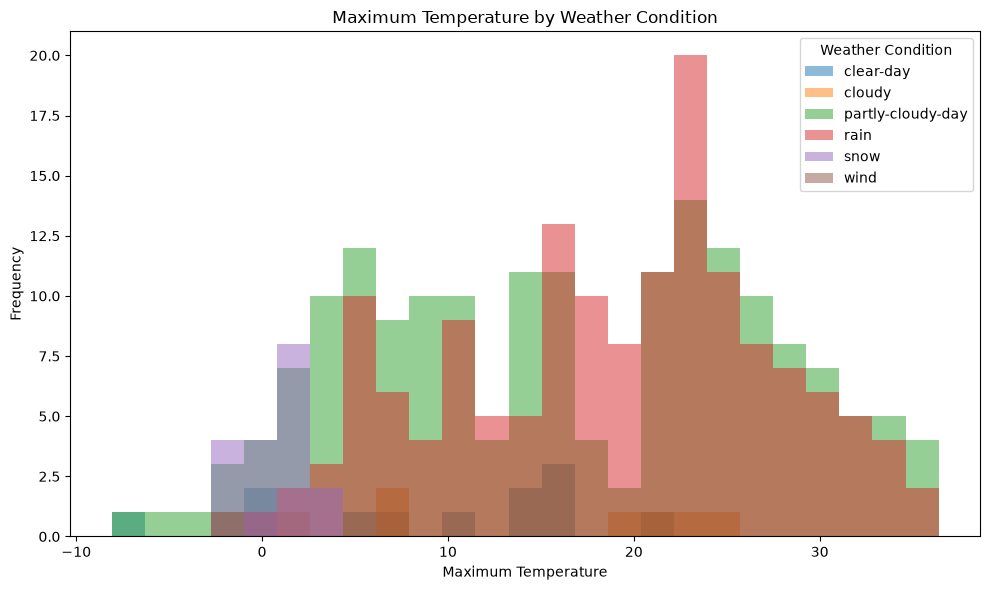

In [19]:
# Your Solution
# Create a chart 
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.histogram_bin_edges(df_weather["tempmax"].dropna(), bins=25)

# Overlay each group's histogram with transparency and a legend label.
for icon, group in grouped_by_icon:
    ax.hist(group["tempmax"].dropna(), bins=bins, alpha=0.5, label=icon)

# Add a title, axis labels, and a legend.
ax.set_title("Maximum Temperature by Weather Condition")
ax.set_xlabel("Maximum Temperature")
ax.set_ylabel("Frequency")
ax.legend(title="Weather Condition")
plt.tight_layout()



**Problem 5**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Create a histogram of the `precip` column for each weather condition group.

Your plot should include:

* 10 bins
* transparency so overlapping distributions can be seen
* a legend
* a title



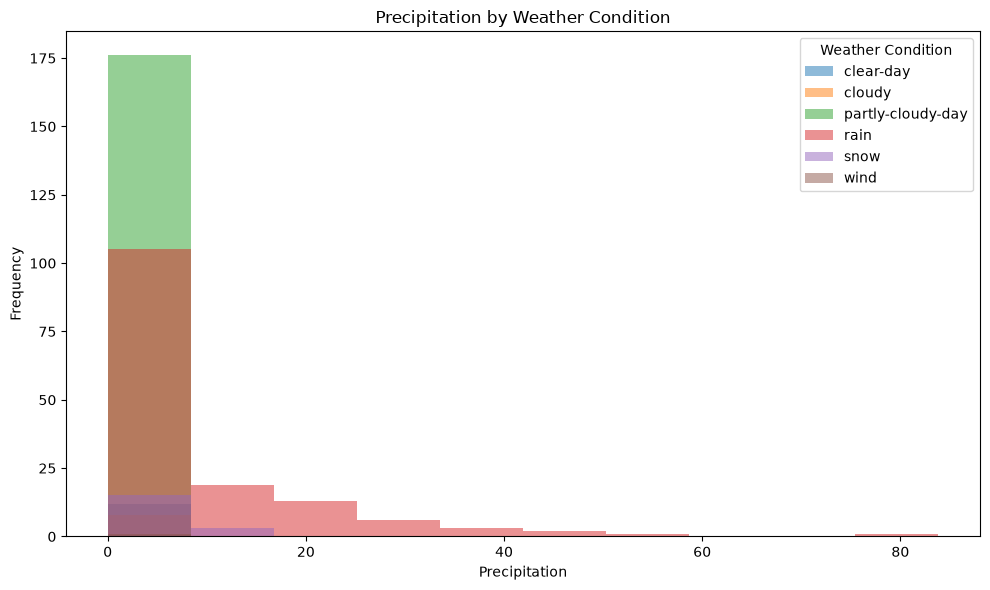

In [20]:
# Your Solution
# Create a chart
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.histogram_bin_edges(df_weather["precip"].dropna(), bins=10)


for icon, group in grouped_by_icon:
    ax.hist(group["precip"].dropna(), bins=bins, alpha=0.5, label=icon)
    
ax.set_title("Precipitation by Weather Condition")
ax.set_xlabel("Precipitation")
ax.set_ylabel("Frequency")
ax.legend(title="Weather Condition")
plt.tight_layout()




**Problem 6**

**Concept:** *Grouping Data, plotting*


**Task:**


Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Compute the **mean** of the `tempmax` column for each weather condition group.
3. Create a **bar chart** to display the mean maximum temperature for each group.


Your plot should include:

* one bar for each weather icon category
* a title



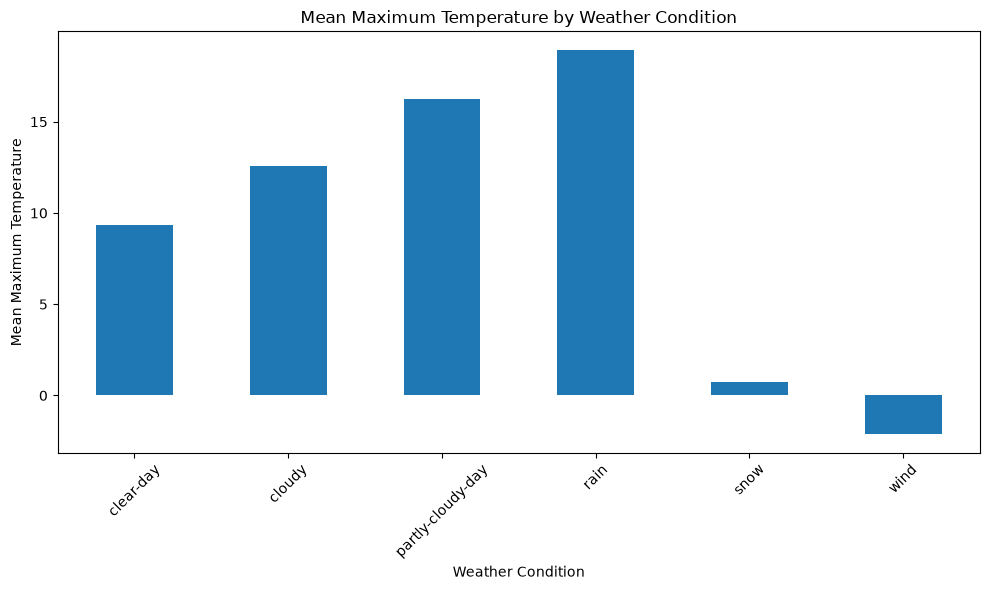

In [21]:
# Your Solution

# Compute the mean maximum temperature 
grouped_tempmax_mean = grouped_by_icon["tempmax"].mean()

# Plot one bar per category with a title and axis labels.
grouped_tempmax_mean.plot.bar(
    title="Mean Maximum Temperature by Weather Condition",
    xlabel="Weather Condition",
    ylabel="Mean Maximum Temperature",
    figsize=(10, 6),
    rot=45,
)
plt.tight_layout()


**Problem 7**

**Concept:** *Grouping data, descriptive statistics*


**Task:**

Using the `02215_weather.csv` dataset:

1. Group the DataFrame by the `icon` column and store the result in a variable named `grouped_by_icon`.
2. Compute descriptive statistics for the `tempmax` column for each group and store the result in a variable named `grouped_tempmax_statistics`.
3. Compute descriptive statistics for the `precip` column for each group and store the result in a variable named `grouped_precipitation_statistics`.
4. Compute the **mean** of the `tempmax` column for each group and store the result in a variable named `grouped_tempmax_mean`.

Print all three results with clear labels:
* `"Tempmax grouped by conditions"`
* `"Precipitation grouped by conditions"`
* `"Mean of tempmax grouped by conditions"`


In [22]:
# Your Solution
# Group the existing weather DataFrame by weather condition.
grouped_by_icon = df_weather.groupby("icon", observed=True)

grouped_tempmax_statistics = grouped_by_icon["tempmax"].describe()
grouped_precipitation_statistics = grouped_by_icon["precip"].describe()
grouped_tempmax_mean = grouped_by_icon["tempmax"].mean()

# Print each result with its required label.
print("Tempmax grouped by conditions")
print(grouped_tempmax_statistics)

print("\nPrecipitation grouped by conditions")
print(grouped_precipitation_statistics)

print("\nMean of tempmax grouped by conditions")
print(grouped_tempmax_mean)



Tempmax grouped by conditions
                   count       mean        std  min    25%    50%     75%  \
icon                                                                        
clear-day           12.0   9.316667   8.230965 -6.4   4.15  12.10  15.225   
cloudy               8.0  12.575000  10.423565 -1.3   4.95  13.05  21.350   
partly-cloudy-day  176.0  16.246023  10.533554 -8.1   7.20  15.65  25.000   
rain               150.0  18.904000   8.498037  0.8  12.60  19.90  24.600   
snow                18.0   0.750000   1.805628 -2.7  -0.65   1.25   1.775   
wind                 1.0  -2.100000        NaN -2.1  -2.10  -2.10  -2.100   

                    max  
icon                     
clear-day          20.8  
cloudy             24.4  
partly-cloudy-day  36.4  
rain               36.4  
snow                4.0  
wind               -2.1  

Precipitation grouped by conditions
                   count      mean        std    min      25%     50%  \
icon                               

QUERYING

The following data frame will be used in several questions.


In [23]:
# starter code
df_voter_data = pd.read_csv("https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-11/newton_voters.csv", low_memory=False)
df_voter_data.index = df_voter_data["Voter ID Number"]
df_voter_data['Date of Birth'] = pd.to_datetime(df_voter_data['Date of Birth'])


**Problem 8**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Determine the **total number of voters** and print the result.
2. Compute the count of voters in each **Party Affiliation** category.
3. Create a **pie chart** showing the distribution of voters by party affiliation.

Your plot should include:
* labels for each category
* a title that includes the total number of voters


Total number of voters: 58769


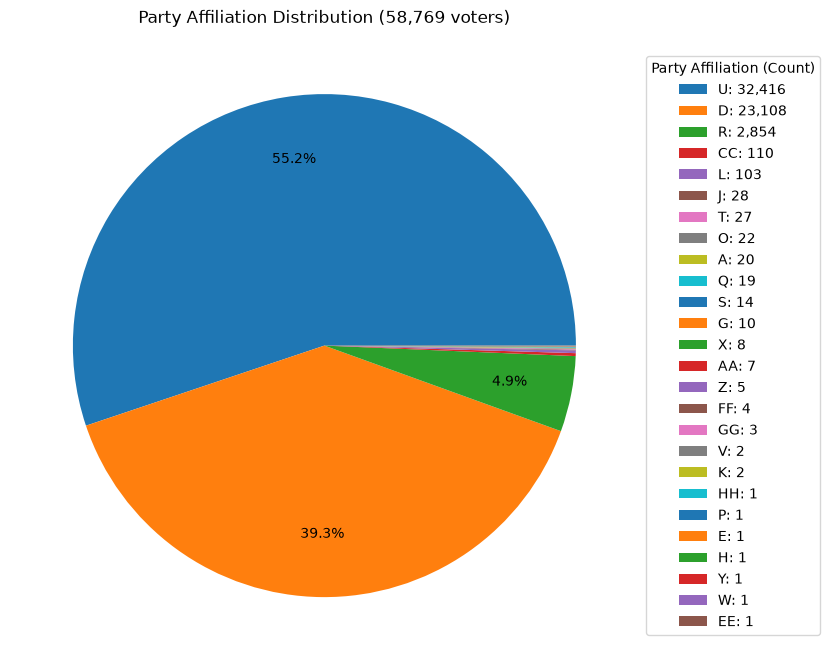

In [28]:
# Your Solution

total_voters = len(df_voter_data)
print(f"Total number of voters: {total_voters}")

# Count voters in each party 
party_counts = df_voter_data["Party Affiliation"].value_counts()

# Plot party counts with category labels and the total in the title.
fig, ax = plt.subplots(figsize=(10, 7))

party_counts.plot.pie(
    ax=ax,
    labels=None,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 1 else "",
    pctdistance=0.75,
    title=f"Party Affiliation Distribution ({total_voters:,} voters)",
    ylabel="",
)

legend_labels = [
    f"{str(party).strip()}: {count:,}"
    for party, count in party_counts.items()
]
ax.legend(
    handles=ax.patches,
    labels=legend_labels,
    title="Party Affiliation (Count)",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
)

plt.tight_layout()






**Problem 9**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Create a new DataFrame named `df_older_voters` that includes only voters born **before January 1, 1950**.
    * Use the `.query()` method
    * Note: use backticks for column names containing spaces
2. Print the total number of voters in this filtered dataset.
3. Compute the count of voters in each **Party Affiliation** category for this subset.
4. Create a **pie chart** showing the distribution of party affiliations among these older voters.

Your plot should include:
* labels for each category
* a title that includes the number of older voters


Total number of older voters: 9,073


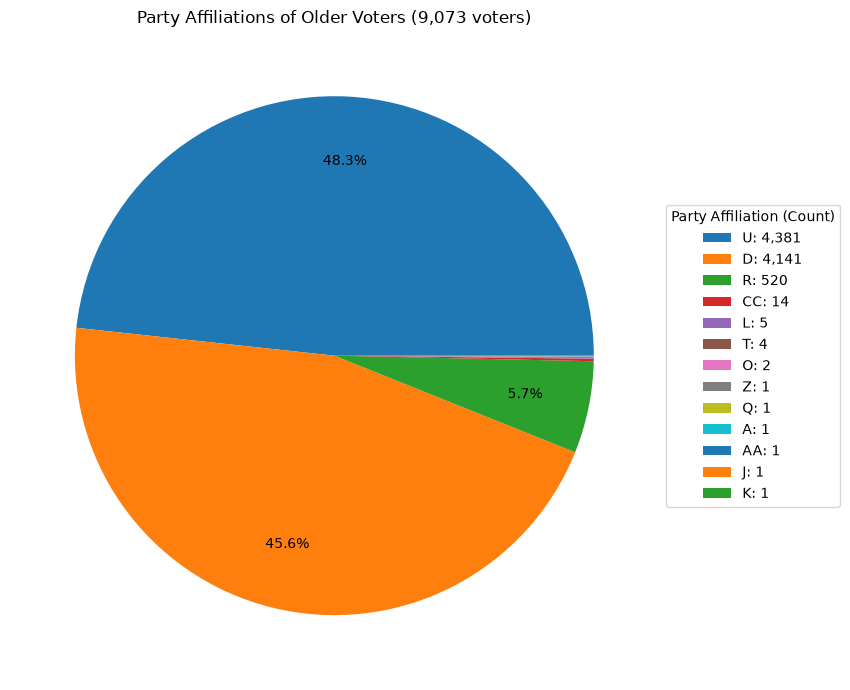

In [29]:
# Your Solution
# Select voters born strictly before January 1, 1950.
df_older_voters = df_voter_data.query("`Date of Birth` < '1950-01-01'")

# Count and print the number of older voters.
total_older_voters = len(df_older_voters)
print(f"Total number of older voters: {total_older_voters:,}")

# Count party affiliations in the filtered dataset.
older_party_counts = df_older_voters["Party Affiliation"].value_counts()

# Plot percentages for larger slices to avoid overlapping text.
fig, ax = plt.subplots(figsize=(10, 7))
older_party_counts.plot.pie(
    ax=ax,
    labels=None,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 1 else "",
    pctdistance=0.75,
    title=f"Party Affiliations of Older Voters ({total_older_voters:,} voters)",
    ylabel="",
)

# Label every category with its exact count in an outside legend.
legend_labels = [
    f"{str(party).strip()}: {count:,}"
    for party, count in older_party_counts.items()
]
ax.legend(
    handles=ax.patches,
    labels=legend_labels,
    title="Party Affiliation (Count)",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
)

# Adjust spacing and display the chart.
plt.tight_layout()




**Problem 10**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Create a new DataFrame named `df_younger_voters` that includes only voters born **after January 1, 2000**.
    * Use the `.query()` method
    * Note: use backticks for column names containing spaces
2. Print the total number of voters in this filtered dataset.
3. Compute the count of voters in each **Party Affiliation** category for this subset.
4. Create a **pie chart** showing the distribution of party affiliations among these Younger voters.

Your plot should include:
* labels for each category
* a title that includes the number of younger voters


Total number of younger voters: 5,099


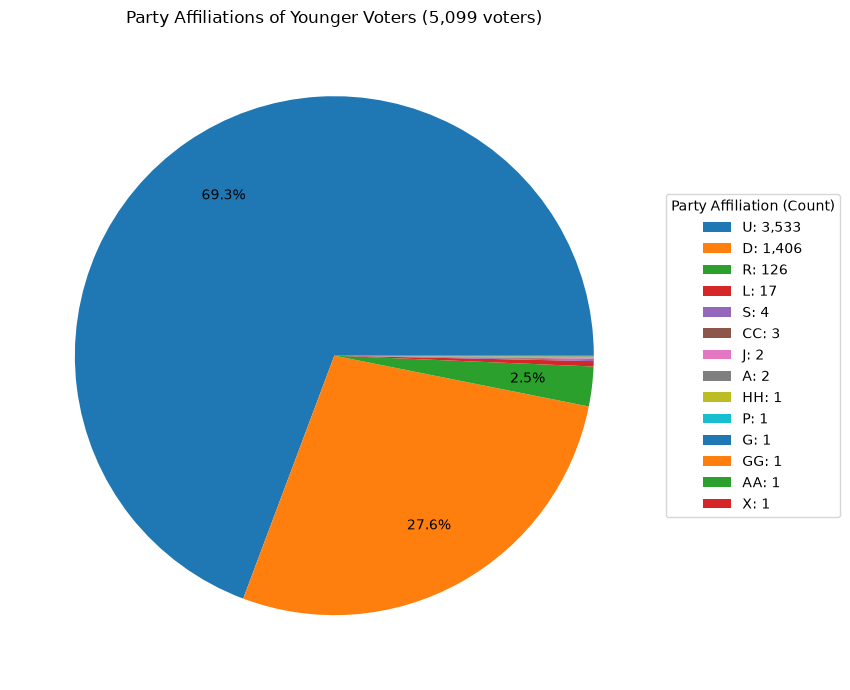

In [30]:
# Your Solution
# Select voters 
df_younger_voters = df_voter_data.query("`Date of Birth` > '2000-01-01'")

# print the number of younger voters.
total_younger_voters = len(df_younger_voters)
print(f"Total number of younger voters: {total_younger_voters:,}")

# Count voters in each party affiliation category.
younger_party_counts = df_younger_voters["Party Affiliation"].value_counts()

# Display percentages on larger slices to avoid overlapping labels.
fig, ax = plt.subplots(figsize=(10, 7))
younger_party_counts.plot.pie(
    ax=ax,
    labels=None,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 1 else "",
    pctdistance=0.75,
    title=f"Party Affiliations of Younger Voters ({total_younger_voters:,} voters)",
    ylabel="",
)

# Label every category with its exact count in the legend.
legend_labels = [
    f"{str(party).strip()}: {count:,}"
    for party, count in younger_party_counts.items()
]
ax.legend(
    handles=ax.patches,
    labels=legend_labels,
    title="Party Affiliation (Count)",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
)

# Adjust spacing and display the chart.
plt.tight_layout()




**Problem 11**

**Concept:** *Querying `DataFrame`s and graphing*



**Task:**

Using the `df_voter_data` DataFrame:
1. Identify all columns related to elections:
    * Select columns whose names contain the letter `"v"` but do **not** contain `"score"`
    * Store the result in a variable named `election_columns`

2. Compute the **voting participation percentage** for each election among all voters:
    * Store the result in a variable named `d1`
    * **Hint:** To calculate participation
        * Use `.sum()` on a column to count how many voters participated
        * Divide by the total number of voters using `len(df)`
        * Multiply by 100 to convert to a percentage

3. Create a filtered DataFrame named `df_high_voter_score`:
    * Include only voters with `voter_score >= 4`
    * Print the number of voters in this group

4. Compute the **voting participation percentage** for this group:
    * Store the result in a variable named `d2`

5. Create a filtered DataFrame named `df_unenrolled`:
    * Include only voters with `"Party Affiliation" == "U "`
    * Print the number of voters in this group

6. Compute the voting participation percentage for this group:
    * Store the result in a variable named `d3`

7. Combine the results into a new DataFrame named `d`:
    * Index should be the election columns
    * Columns should be:
        * `"all voters"`
        * `"high-propensity voters"`
        * `"unenrolled voters"`

8. Create a **bar chart** from this combined DataFrame.

Your plot should include:
* a title
* a key

High-propensity voters: 15,245
Unenrolled voters: 32,416


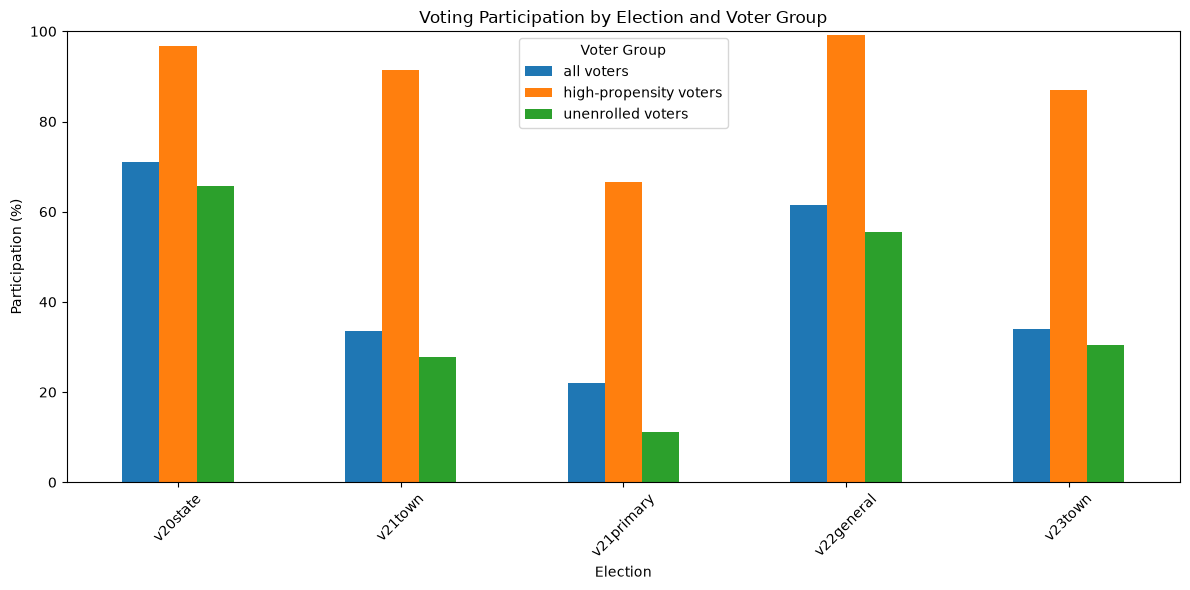

In [31]:
# Your Solution

# Select columns containing lowercase "v"
election_columns = [
    column for column in df_voter_data.columns
    if "v" in column and "score" not in column
]

# Calculate participation percentages among all voters.
d1 = df_voter_data[election_columns].sum() / len(df_voter_data) * 100

# Select high-propensity voters and print their count.
df_high_voter_score = df_voter_data.query("voter_score >= 4")
print(f"High-propensity voters: {len(df_high_voter_score):,}")

# Calculate participation percentages among high-propensity voters.
d2 = (
    df_high_voter_score[election_columns].sum()
    / len(df_high_voter_score) * 100
)

# Select unenrolled voters
df_unenrolled = df_voter_data.query("`Party Affiliation` == 'U '")
print(f"Unenrolled voters: {len(df_unenrolled):,}")

# Calculate participation percentages among unenrolled voters.
d3 = df_unenrolled[election_columns].sum() / len(df_unenrolled) * 100

# Combine the percentages, aligning results by election column.
d = pd.DataFrame(
    {
        "all voters": d1,
        "high-propensity voters": d2,
        "unenrolled voters": d3,
    },
    index=election_columns,
)

# Plot grouped bars with a title, axis labels, and a key.
ax = d.plot.bar(
    figsize=(12, 6),
    title="Voting Participation by Election and Voter Group",
    xlabel="Election",
    ylabel="Participation (%)",
    rot=45,
    legend=True,
)
ax.set_ylim(0, 100)
ax.legend(title="Voter Group")
plt.tight_layout()



**Problem 12**

**Concept:** *Joining `DataFrame`s*


**Task:**

You are given two DataFrames:
* `submissions`, which contains student IDs and their homework submission IDs
* `grades`, which contains homework grades indexed by submission ID

Using these DataFrames:
1. Inspect both DataFrames by printing them.
2. Join the `submissions` DataFrame with the `grades` DataFrame:
    * Match the `hw1_submission` column in `submissions` with the index of `grades`
    * Store the result in a variable named `result`
3. Update the index of the resulting DataFrame:
    * Set the index to the `student_id` column
4. Create a new DataFrame named `result_df`:
    * Remove the `student_id` column
5. Print the final DataFrame


Starter code:

In [32]:
# STARTER CODE:
submissions = pd.DataFrame(data={"student_id": ["U100", "U101", "U102", "U103", "U104"],
                        "hw1_submission": ["c1325", "b231", "a512", "e9999", "d8234"]})

grades = pd.DataFrame(index=["a512", "b231", "c1325", "d8234", "e9999"],
                        data={"hw1_grade": [0.99, 0.50, 0.62, 0.78, 1.00]} )


In [33]:
# Your Solution

# DataFrames.
print("Submissions:")
print(submissions)
print("\nGrades:")
print(grades)

# Match submission IDs to the grades index.
result = submissions.join(grades, on="hw1_submission")

# Set student IDs as the index while retaining the column temporarily.
result = result.set_index("student_id", drop=False)

# Create a new DataFrame without the redundant student_id column.
result_df = result.drop(columns="student_id")

# Print the final DataFrame.
print("\nFinal DataFrame:")
print(result_df)


Submissions:
  student_id hw1_submission
0       U100          c1325
1       U101           b231
2       U102           a512
3       U103          e9999
4       U104          d8234

Grades:
       hw1_grade
a512        0.99
b231        0.50
c1325       0.62
d8234       0.78
e9999       1.00

Final DataFrame:
           hw1_submission  hw1_grade
student_id                          
U100                c1325       0.62
U101                 b231       0.50
U102                 a512       0.99
U103                e9999       1.00
U104                d8234       0.78


**Problem 13**

**Concept:** *Joining `DataFrame`s*



**Task:**

You are given two datasets:
* `design_materials.tsv`, which contains materials and the quantity required per bed
* `material_costs.tsv`, which contains the cost per unit for each material

Using these datasets:
1. Load both datasets from the provided `.tsv` files using the correct separator.
2. Merge the two DataFrames:
    * Join on the `material` column
    * Store the result in a variable named `df_costs`
3. Create a new column named `cost`:
    * Compute it as:

      **quantity_per_bed × unit_cost**
4. Print the resulting DataFrame

In [ ]:
# Your Solution
# Load the tab-separated datasets.
df_design_materials = pd.read_csv("design_materials.tsv", sep="\t")
df_material_costs = pd.read_csv("material_costs.tsv", sep="\t")

# Merge the datasets using their shared material column.
df_costs = df_design_materials.merge(df_material_costs, on="material")

# material cost per bed.
df_costs["cost"] = df_costs["quantity_per_bed"] * df_costs["unit_cost"]

# Result
print(df_costs)



          design                    material  quantity_per_bed  unit_cost  \
0  4' x 4' x 18"                2" x 6" x 4'                20       5.92   
1  4' x 4' x 18"  8" x 8" x 16" Cinder Block                12       3.53   
2  4' x 8' x 18"                2" x 6" x 4'                 6       5.92   
3  4' x 8' x 18"                2" x 6" x 8'                14       7.62   
4  4' x 8' x 18"  8" x 8" x 16" Cinder Block                24       3.53   
5  4' x 4' x 12"                2" x 6" x 4'                16       5.92   
6  4' x 4' x 12"  8" x 8" x 16" Cinder Block                12       3.53   
7  4' x 8' x 12"                2" x 6" x 4'                 2       5.92   
8  4' x 8' x 12"                2" x 6" x 8'                12       7.62   
9  4' x 8' x 12"  8" x 8" x 16" Cinder Block                24       3.53   

     cost  
0  118.40  
1   42.36  
2   35.52  
3  106.68  
4   84.72  
5   94.72  
6   42.36  
7   11.84  
8   91.44  
9   84.72  


**Problem 14**

**Concept:** *joining `DataFrame`s*


**Task:**

You are given three stock datasets:
* BAC
* GM
* SBUX

Using these datasets:
1. Load each dataset into separate DataFrames:
    * `df_bac`, `df_gm`, and `df_sbux`
2. Convert the `date` column in each DataFrame to pandas datetime format and set it as the index.
3. Create a new DataFrame named `df_stock_prices`:
    * Use the index from `df_bac`
    * Add the following columns:
        * `"bac"` from `df_bac["close"]`
        * `"gm"` from `df_gm["close"]`
        * `"sbux"` from `df_sbux["close"]`
4. Create a **line plot** showing the stock prices over time.

Your plot should include:
* all three stocks on the same chart
* a title

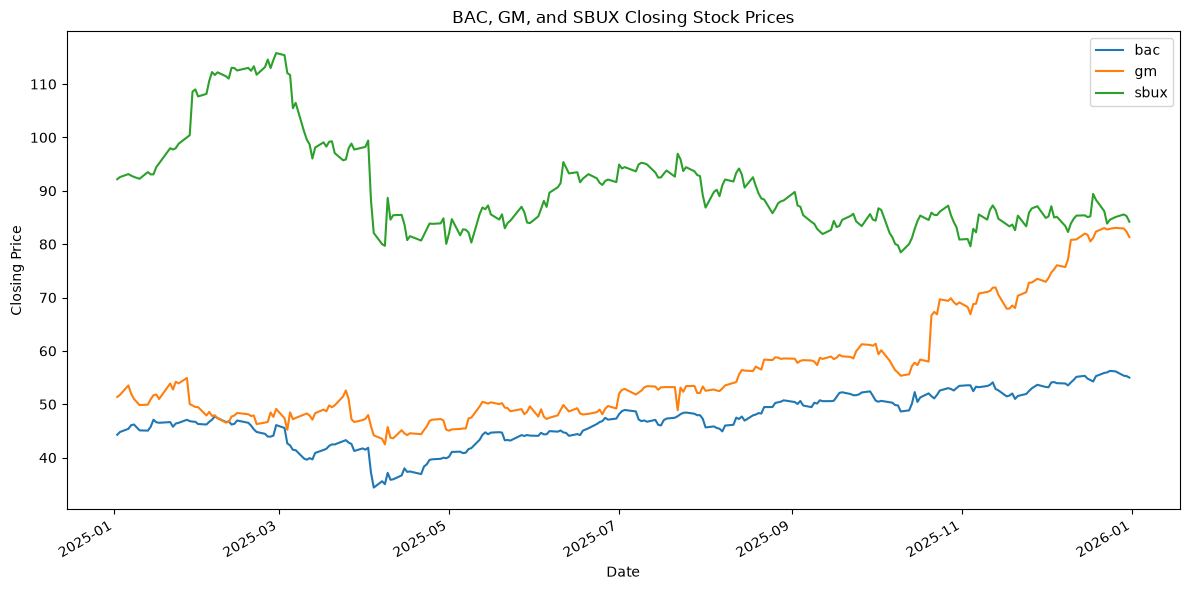

In [35]:
# Your Solution
# Load each stock dataset.
df_bac = pd.read_csv("BAC.csv")
df_gm = pd.read_csv("GM.csv")
df_sbux = pd.read_csv("SBUX.csv")

# Convert Unix timestamps to dates and set each DataFrame's index.
for df in [df_bac, df_gm, df_sbux]:
    df["date"] = pd.to_datetime(df["date"], unit="s").dt.normalize()
    df.set_index("date", inplace=True)
    df.sort_index(inplace=True)

# Align closing prices using the BAC date index.
df_stock_prices = pd.DataFrame(index=df_bac.index)
df_stock_prices["bac"] = df_bac["close"]
df_stock_prices["gm"] = df_gm["close"]
df_stock_prices["sbux"] = df_sbux["close"]

# Plot all three stocks together with a title and legend.
df_stock_prices.plot(
    figsize=(12, 6),
    title="BAC, GM, and SBUX Closing Stock Prices",
    xlabel="Date",
    ylabel="Closing Price",
    legend=True,
)
plt.tight_layout()




**Problem 15**

**Concept:** *joining `DataFrame`s*


**Task:**

Using the `df_stock_prices` DataFrame from **Problem 14**:
1. Compute the **relative prices** of each stock:
    * Divide all values by the first row of the DataFrame
    * Store the result in a variable named `df_stock_prices_relative`
2. Create a **line plot** of the relative prices.

Your plot should include:
* all three stocks on the same chart
* a title

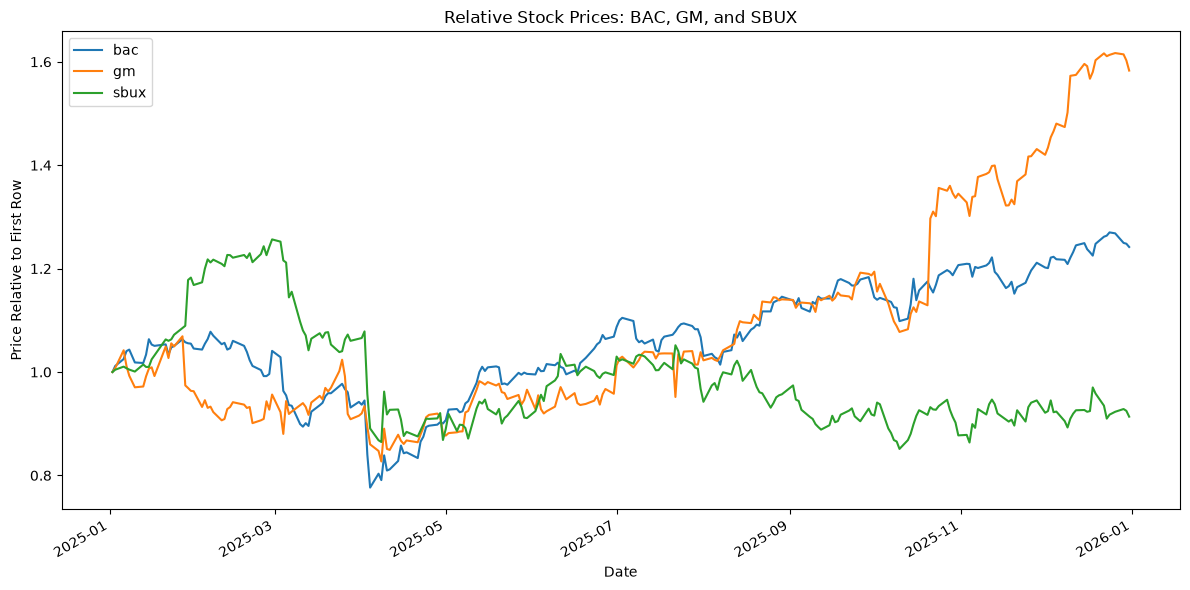

In [36]:
# Your Solution

df_stock_prices_relative = df_stock_prices / df_stock_prices.iloc[0]

# Plot all three stocks' relative prices together.
df_stock_prices_relative.plot(
    figsize=(12, 6),
    title="Relative Stock Prices: BAC, GM, and SBUX",
    xlabel="Date",
    ylabel="Price Relative to First Row",
    legend=True,
)

# Adjust spacing and display the chart.
plt.tight_layout()


